In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from ipynb.fs.full.model import build_nn_model, train_model, plot_loss, plot_mae, evaluate_model,plot_loss_and_mae

from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import tensorflow as tf

I0000 00:00:1794306362.669181 1652717 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794306362.701262 1652717 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794306363.407636 1652717 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


<h1> Import Data and remove NANs

Text(0.5, 0.98, 'All Data')

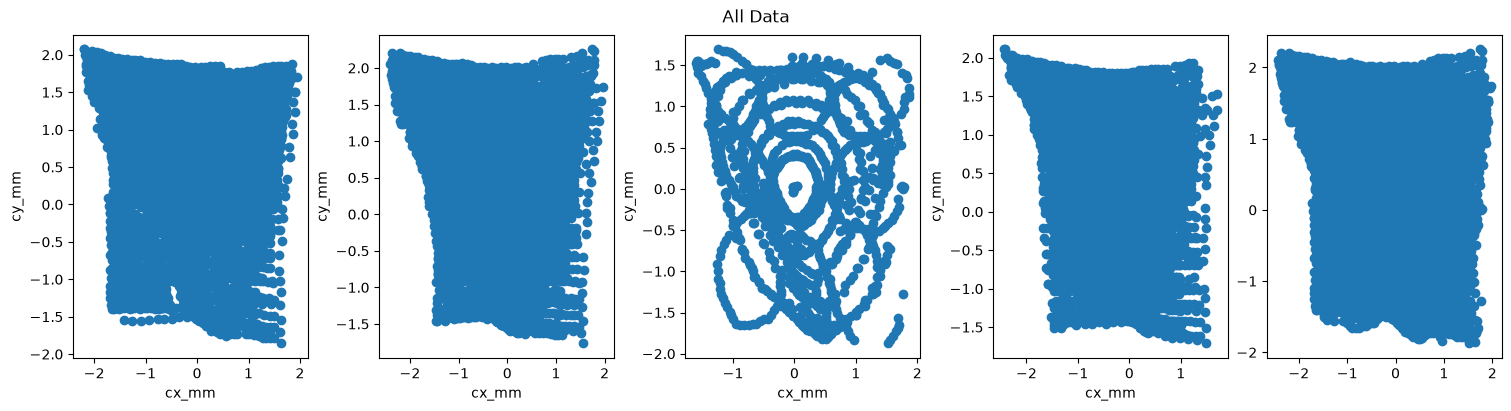

In [3]:
data_0 = pd.read_csv("processed_data/16Oct_data_corrected.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_1 = pd.read_csv("processed_data/27Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_2 = pd.read_csv("processed_data/28Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_3 = pd.read_csv("processed_data/29Oct_data.csv", dtype="float32") #data was saved as float32, by default this was importing as float64
data_0 = data_0.dropna()
data_1 = data_1.dropna()
data_2 = data_2.dropna()
data_3 = data_3.dropna()
data_list = [data_0, data_1, data_2, data_3]

all_data = pd.concat(data_list, ignore_index=True)

fig, axs = plt.subplots(1, 5, figsize=(15,4), constrained_layout=True)
for i, data in enumerate(data_list):
    subplot = axs[i]
    subplot.scatter(data["cx_mm"], data["cy_mm"])
    subplot.set_xlabel("cx_mm")
    subplot.set_ylabel("cy_mm")
axs[4].scatter(all_data["cx_mm"], all_data["cy_mm"])
fig.suptitle("All Data")

<h2> Add names?

In [ ]:
# data_0.Name = "data_0"
# data_1.Name = "data_1"
# data_2.Name = "data_2"
# data_3.Name = "data_3"

<h2> Create StandardScalers based on all data

In [4]:
scalerX = StandardScaler().fit(all_data[["cx_mm", "cy_mm"]])
scalerY = StandardScaler().fit(all_data[["s0", "s1", "s2"]])

<h2>Scale all datasets

In [ ]:
scaled = {}
for i, data in enumerate(data_list):
    scaled[f"X_scaled_{i}"] = scalerX.transform(data[["cx_mm", "cy_mm"]])
    scaled[f"y_scaled_{i}"] = scalerY.transform(data[["s0", "s1", "s2"]])
    plt.scatter(scaled[f"X_scaled_{i}"][:,0], scaled[f"X_scaled_{i}"][:,1], label=f"data_{i}")
    plt.legend()

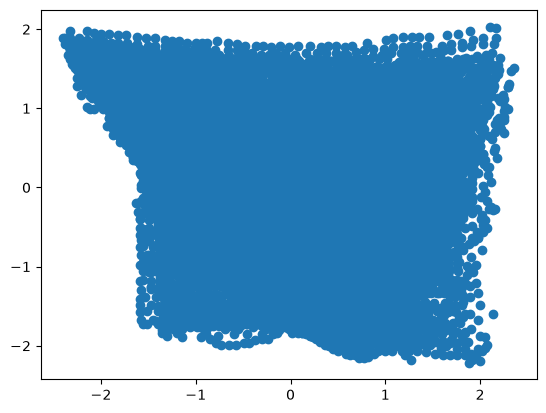

In [6]:
X_scaled_all = scalerX.transform(all_data[["cx_mm", "cy_mm"]])
y_scaled_all = scalerY.transform(all_data[["s0", "s1", "s2"]])
plt.scatter(X_scaled_all[:,0], X_scaled_all[:,1])

In [7]:
def plot_motors(y_test, y_pred, lims): 
    fig, axs = plt.subplots(1, 3)

    for i,motor in enumerate(["s0", "s1", "s2"]):
        subplot = axs[i]
        subplot.scatter(y_test[:,i], y_pred[:,i])
        subplot.set_xlabel('True Values')
        subplot.set_ylabel('Predictions')
        _ =subplot.plot(lims, lims, color="red")
        subplot.set_title(motor)
        subplot.plot()

<h1>Linear Regression

Fold, 0:
  Train: index=0 to 3166 
  Test:  index=3167 to 6330

Linear Regression Results:
  Overall R2:  0.9528
  Weighted R2: 0.9521
Fold, 1:
  Train: index=0 to 6330 
  Test:  index=6331 to 9494

Linear Regression Results:
  Overall R2:  0.9281
  Weighted R2: 0.9323
Fold, 2:
  Train: index=0 to 9494 
  Test:  index=9495 to 12658

Linear Regression Results:
  Overall R2:  0.9278
  Weighted R2: 0.9276
MSE scores for each fold: [0.04550060257315636, 0.06878852844238281, 0.06866031885147095]


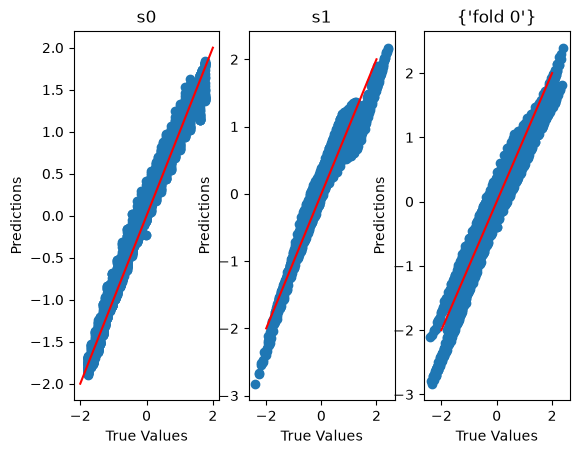

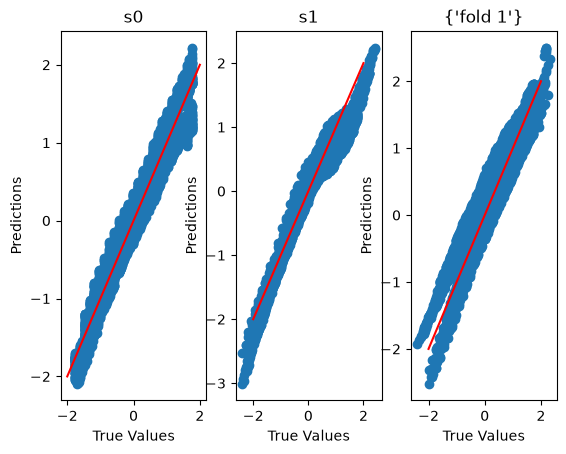

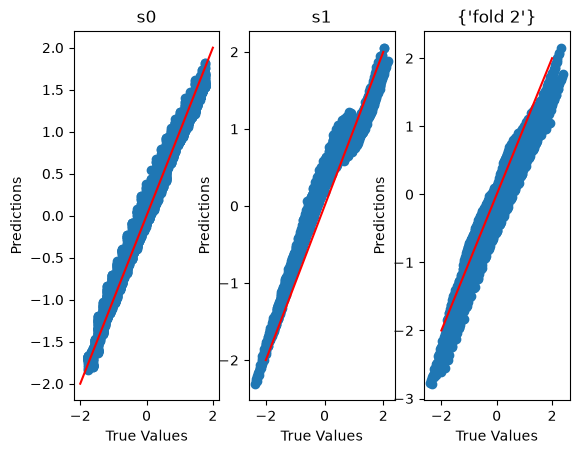

In [ ]:
#LR sklearn - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    lin_reg = LinearRegression()
    lin_reg.fit(X_train, y_train)
    y_pred = lin_reg.predict(X_test)
    evaluate_model("Linear Regression", y_test, y_pred)

    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

In [16]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
# plt.scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
# plt.colorbar()
# plt.title("x and y values input into snake scan. (color=index)")
snake_predictions = lin_reg.predict(mesh0045_27Oct[["x", "y"]])
snake_pred_inverse = scalerY.inverse_transform(snake_predictions)
print(snake_pred_inverse)
np.savetxt("predictions/all_data_LR_Pred_snake_mesh.csv", snake_pred_inverse, delimiter=',')

[[ 4575.48200152 -5874.33811363  1298.85452931]
 [ 4545.95077215 -5566.87038404  1020.91804446]
 [ 4516.41954279 -5259.40265445   742.98155961]
 ...
 [-4401.84305464  5558.58050081 -1156.73575263]
 [-4431.37428401  5866.0482304  -1434.67223748]
 [-4460.90551337  6173.51595999 -1712.60872232]]


/scratch/dvu71330/grad_project_3/DeltabotProject/TensorFlow/.venv/lib64/python3.12/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


<h2> LR with tensorflow

Fold, 0:
  Train: index=0 to 3166 
  Test:  index=3167 to 6330

Fold: 0 Results (scaled):
  Overall R2:  0.3683
  Weighted R2: 0.4112
Fold, 1:
  Train: index=0 to 6330 
  Test:  index=6331 to 9494

Fold: 1 Results (scaled):
  Overall R2:  0.4836
  Weighted R2: 0.5145
Fold, 2:
  Train: index=0 to 9494 
  Test:  index=9495 to 12658

Fold: 2 Results (scaled):
  Overall R2:  0.4821
  Weighted R2: 0.4805
MSE scores for each fold: [0.5591675639152527, 0.49321088194847107, 0.49290791153907776]


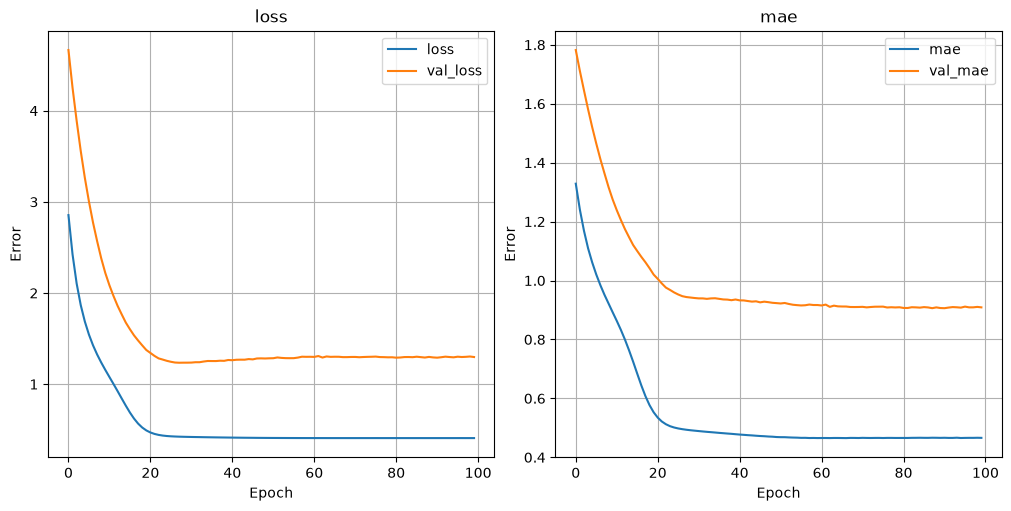

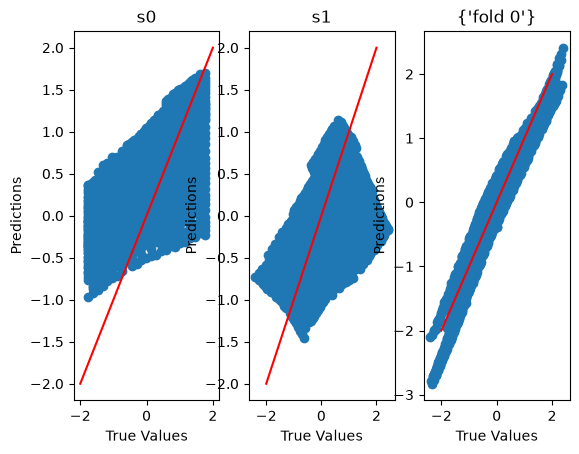

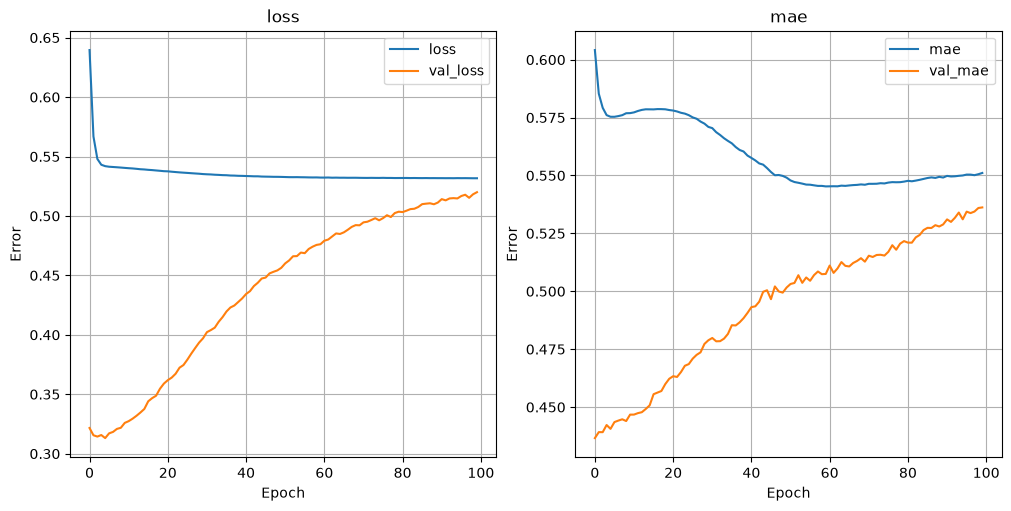

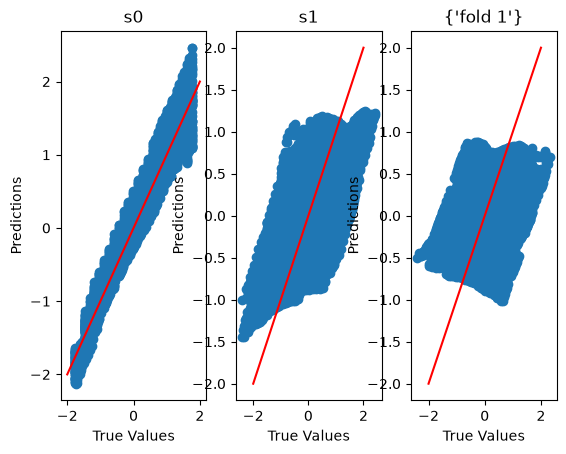

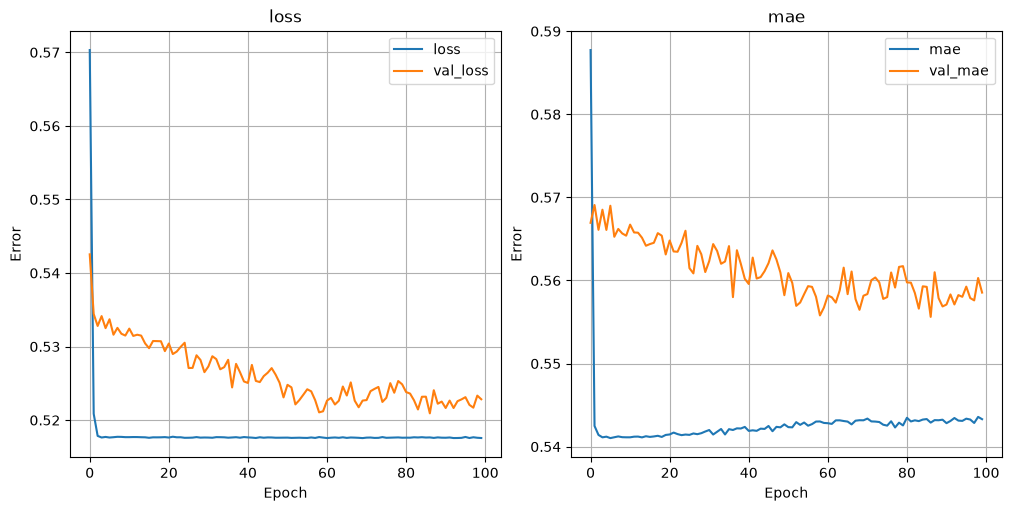

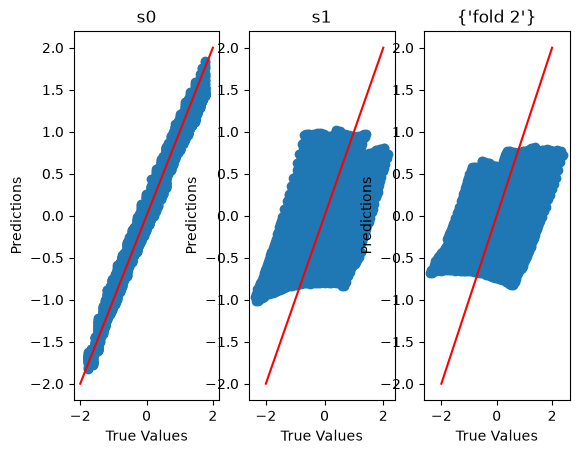

In [22]:
#LR tensorflow - all data concat trained. 
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model =  tf.keras.models.Sequential(
    [
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(
            units=1, activation="linear"
        ),  # Linear activation = Linear Regression
        tf.keras.layers.Dense(y_train.shape[1],)
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae'])
    

    history = train_model(model, X_train, y_train, verbose=0, epochs=100, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)

    plot_loss_and_mae(history)

    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plt.title({f"fold {i}"})

print("MSE scores for each fold:", scores)

<h1>MLP

In [ ]:
def build_nn_model(input_dim, output_dim, architecture='standard'):
    """Build a neural network model with specified architecture"""
    
    if architecture == 'standard':
        model = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(output_dim)
        ])

    model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae'])

    return model

def train_model(model, X_train, y_train, epochs=100, patience=30, verbose=0):
    # callbacks = [
    # tf.keras.callbacks.EarlyStopping(
    #     monitor='val_loss',
    #     patience=patience,
    #     restore_best_weights=True
    # )]

    history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    verbose=verbose, 
    epochs=epochs,
    # callbacks=callbacks
    )
    print(patience)
    return history

In [ ]:
# training pm data adding each data set separately 
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

# X = X_scaled_all
# y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for data in range(4):
    X = scaled[f"X_scaled_{data}"]
    y = scaled[f"y_scaled_{data}"]
    for i, (train_index, test_index) in enumerate(tscv.split(X)):
        print(f"Fold{data}, {i}:")
        print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
        print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
        
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        model = build_nn_model(X_train.shape[1], y_train.shape[1])

        history = train_model(model, X_train, y_train, verbose=0, epochs=50, patience=1)
        y_pred = model.predict(X_test, verbose=0)

        evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
        # plot_motors(y_test, y_pred, [-2,2])

        error = mean_squared_error(y_test, y_pred)
        scores.append(error)
        plot_loss_and_mae(history)
        plt.title({f"Data {data}, fold {i}"})

print("MSE scores for each fold:", scores)

In [ ]:
#Training with all data concatenated
# model = build_nn_model(2, 3) #usually not hardcoded - X_train_scaled.shape[1], y_train_scaled.shape[1]
# model.summary() #investigate
scores = []

X = X_scaled_all
y = y_scaled_all

tscv = TimeSeriesSplit(n_splits=3) #, test_size=712
for i, (train_index, test_index) in enumerate(tscv.split(X)):
    print(f"Fold{data}, {i}:")
    print(f"  Train: index={train_index[0]} to {train_index[-1]} ")
    print(f"  Test:  index={test_index[0]} to {test_index[-1]}")
    
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]

    model = build_nn_model(X_train.shape[1], y_train.shape[1])

    history = train_model(model, X_train, y_train, verbose=0, epochs=500, patience=1)
    y_pred = model.predict(X_test, verbose=0)

    evaluate_model(f"Fold: {i}", y_test, y_pred, is_scaled=True)
    plot_motors(y_test, y_pred, [-2,2])

    error = mean_squared_error(y_test, y_pred)
    scores.append(error)
    plot_loss_and_mae(history)
    plt.title({f"Data {data}, fold {i}"})

print("MSE scores for each fold:", scores)

In [ ]:
len(X_train)